Dimensiones del dataset: (20640, 9)

Tipos de datos y valores nulos:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   MedHouseVal  20640 non-null  float64
dtypes: float64(2)
memory usage: 322.6 KB
None

Valores nulos por columna:
 MedInc         0
MedHouseVal    0
dtype: int64

Resumen estadístico:
              MedInc   MedHouseVal
count  20640.000000  20640.000000
mean       3.870671      2.068558
std        1.899822      1.153956
min        0.499900      0.149990
25%        2.563400      1.196000
50%        3.534800      1.797000
75%        4.743250      2.647250
max       15.000100      5.000010

Intercepto (b0): 0.4446
Pendiente / Coeficiente (b1 - MedInc): 0.4193
MSE:  0.7091
RMSE: 0.8421
R²:   0.4589


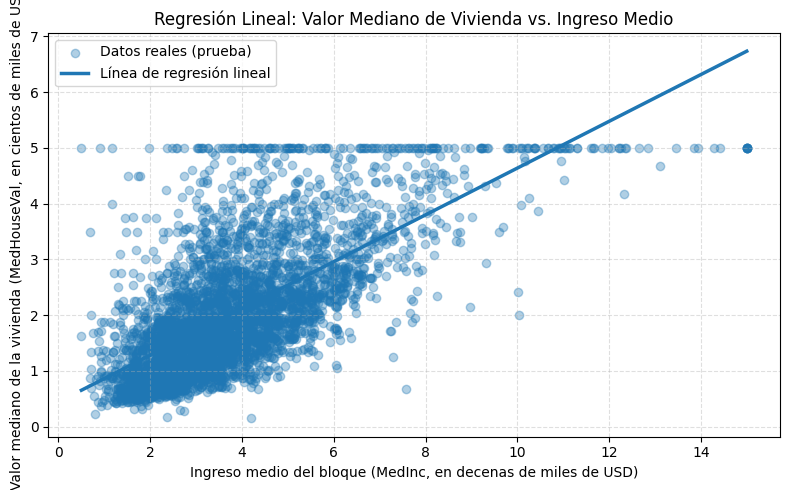

In [1]:
# 1. Importar librerías necesarias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Semilla fija para reproducibilidad
SEED = 42

# 2. Cargar dataset y construir DataFrame
housing = fetch_california_housing(as_frame=True)
df = housing.frame.copy()

print("Dimensiones del dataset:", df.shape)
print("\nTipos de datos y valores nulos:")
print(df[["MedInc", "MedHouseVal"]].info())
print("\nValores nulos por columna:\n", df[["MedInc", "MedHouseVal"]].isna().sum())
print("\nResumen estadístico:\n", df[["MedInc", "MedHouseVal"]].describe())

# 3. Definir matriz de características X (2D) y variable objetivo y (1D)
X = df[["MedInc"]]
y = df["MedHouseVal"]

# 4. Dividir en entrenamiento (80%) y prueba (20%) con random_state=42
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED
)

# 5. Entrenar modelo de Regresión Lineal
modelo_lr = LinearRegression()
modelo_lr.fit(X_train, y_train)

# 6. Predecir sobre el conjunto de prueba
y_pred = modelo_lr.predict(X_test)

# 7. Calcular métricas de evaluación (MSE, RMSE y R²)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"\nIntercepto (b0): {modelo_lr.intercept_:.4f}")
print(f"Pendiente / Coeficiente (b1 - MedInc): {modelo_lr.coef_[0]:.4f}")
print(f"MSE:  {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²:   {r2:.4f}")

# 8. Gráfico de dispersión con la línea de regresión ajustada
plt.figure(figsize=(8, 5))
plt.scatter(X_test["MedInc"], y_test, alpha=0.35, label="Datos reales (prueba)")

# Ordenar X_test para trazar una línea limpia de regresión
orden = np.argsort(X_test["MedInc"].values)
x_sorted = X_test["MedInc"].values[orden]
y_pred_sorted = y_pred[orden]

plt.plot(x_sorted, y_pred_sorted, linewidth=2.5, label="Línea de regresión lineal")
plt.title("Regresión Lineal: Valor Mediano de Vivienda vs. Ingreso Medio")
plt.xlabel("Ingreso medio del bloque (MedInc, en decenas de miles de USD)")
plt.ylabel("Valor mediano de la vivienda (MedHouseVal, en cientos de miles de USD)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

Dimensiones: (200, 2)
Nulos por columna:
 Ingreso_Anual_kUSD     0
Puntaje_Gasto_1_100    0
dtype: int64
Filas duplicadas: 0

Evaluación de k:
k = 2 | Inercia = 231.05 | Silhouette Score = 0.4121
k = 3 | Inercia = 139.67 | Silhouette Score = 0.5108
k = 4 | Inercia = 61.23 | Silhouette Score = 0.6338
k = 5 | Inercia = 20.37 | Silhouette Score = 0.7226
k = 6 | Inercia = 18.33 | Silhouette Score = 0.6459
k = 7 | Inercia = 16.58 | Silhouette Score = 0.5731


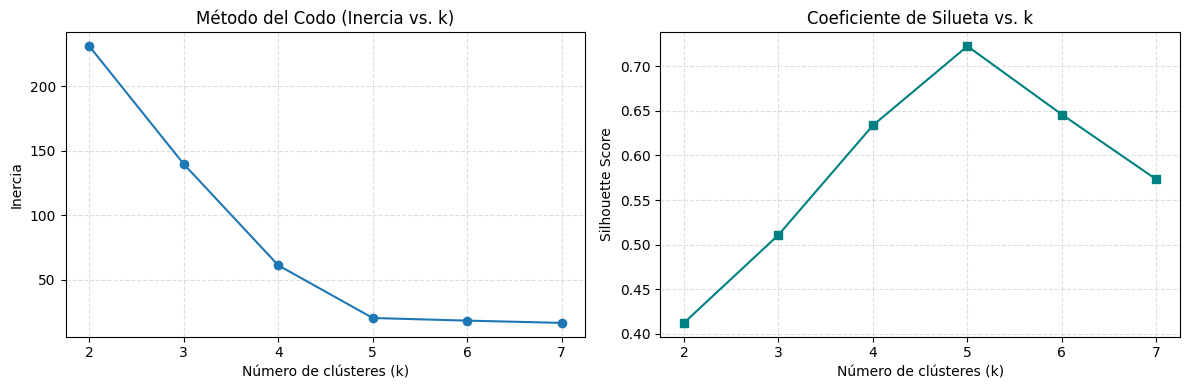


Perfil y centroides en escala original:
   Cluster  Tamano  Centroide_Ingreso_kUSD  Centroide_Gasto
0        0      38                   54.55            51.52
1        1      40                   24.51            80.42
2        2      40                   24.08            19.51
3        3      41                   86.30            19.53
4        4      41                   84.64            82.47


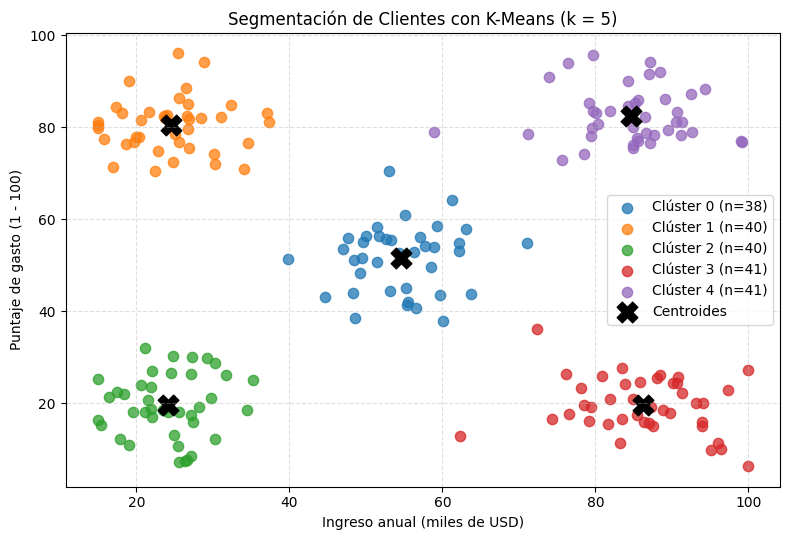

In [2]:
# 1. Importar librerías necesarias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

SEED = 42

# 2. Generar dataset estilo Mall Customers (200 clientes, 5 segmentos naturales)
# (También puedes cargar Mall_Customers.csv desde URL/Drive si lo tienes en Colab)
centros_reales = [
    [25, 20],   # Bajo ingreso, bajo gasto
    [25, 80],   # Bajo ingreso, alto gasto
    [55, 50],   # Ingreso medio, gasto medio
    [85, 20],   # Alto ingreso, bajo gasto
    [85, 82],   # Alto ingreso, alto gasto
]
X_raw, _ = make_blobs(
    n_samples=200,
    centers=centros_reales,
    cluster_std=[6.5, 6.5, 7.5, 7.0, 6.5],
    random_state=SEED,
)

df_clientes = pd.DataFrame(X_raw, columns=["Ingreso_Anual_kUSD", "Puntaje_Gasto_1_100"])
df_clientes["Ingreso_Anual_kUSD"] = df_clientes["Ingreso_Anual_kUSD"].clip(15, 137).round(1)
df_clientes["Puntaje_Gasto_1_100"] = df_clientes["Puntaje_Gasto_1_100"].clip(1, 99).round(1)

# 3. Verificar ausencia de nulos y duplicados
print("Dimensiones:", df_clientes.shape)
print("Nulos por columna:\n", df_clientes.isna().sum())
print("Filas duplicadas:", df_clientes.duplicated().sum())

# 4. Escalamiento estándar (media 0, desviación estándar 1)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_clientes)

# 5. Evaluar k de 2 a 7 con Método del Codo (Inercia) y Silhouette Score
valores_k = range(2, 8)
inercias = []
silhouettes = []

print("\nEvaluación de k:")
for k in valores_k:
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=SEED)
    etiquetas = km.fit_predict(X_scaled)
    inercia = km.inertia_
    sil = silhouette_score(X_scaled, etiquetas)
    inercias.append(inercia)
    silhouettes.append(sil)
    print(f"k = {k} | Inercia = {inercia:.2f} | Silhouette Score = {sil:.4f}")

# Gráfico de apoyo: Método del Codo y Silhouette Score
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(valores_k, inercias, marker="o")
ax[0].set_title("Método del Codo (Inercia vs. k)")
ax[0].set_xlabel("Número de clústeres (k)")
ax[0].set_ylabel("Inercia")
ax[0].grid(True, linestyle="--", alpha=0.4)

ax[1].plot(valores_k, silhouettes, marker="s", color="teal")
ax[1].set_title("Coeficiente de Silueta vs. k")
ax[1].set_xlabel("Número de clústeres (k)")
ax[1].set_ylabel("Silhouette Score")
ax[1].grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

# 6. Entrenar modelo final con el k elegido (cambia a 4 si deseas 4 grupos exactos)
K_OPTIMO = 5
kmeans_final = KMeans(n_clusters=K_OPTIMO, init="k-means++", n_init=10, random_state=SEED)
df_clientes["Cluster"] = kmeans_final.fit_predict(X_scaled)

# 7. Obtener centroides en escala original y perfil promedio por clúster
centroides_orig = scaler.inverse_transform(kmeans_final.cluster_centers_)
df_centroides = pd.DataFrame(
    centroides_orig, columns=["Centroide_Ingreso_kUSD", "Centroide_Gasto"]
)
df_centroides["Cluster"] = range(K_OPTIMO)
df_centroides["Tamano"] = df_clientes["Cluster"].value_counts().sort_index().values

print("\nPerfil y centroides en escala original:")
print(df_centroides[["Cluster", "Tamano", "Centroide_Ingreso_kUSD", "Centroide_Gasto"]].round(2))

# 8. Visualización de clústeres coloreados y centroides marcados
plt.figure(figsize=(8, 5.5))
for c in range(K_OPTIMO):
    sub = df_clientes[df_clientes["Cluster"] == c]
    plt.scatter(
        sub["Ingreso_Anual_kUSD"],
        sub["Puntaje_Gasto_1_100"],
        s=55,
        alpha=0.75,
        label=f"Clúster {c} (n={len(sub)})",
    )

plt.scatter(
    centroides_orig[:, 0],
    centroides_orig[:, 1],
    c="black",
    marker="X",
    s=220,
    label="Centroides",
)
plt.title(f"Segmentación de Clientes con K-Means (k = {K_OPTIMO})")
plt.xlabel("Ingreso anual (miles de USD)")
plt.ylabel("Puntaje de gasto (1 - 100)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()